In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
import os
from pathlib import Path
import openpyxl
import sqlalchemy as sa

# Desactivar notación científica
pd.set_option('display.float_format', lambda x: '%.3f' % x)
np.set_printoptions(suppress=True)

#RUTAS
# ── Rutas del proyecto ────────────────────────────────────────────────
# Se resuelven desde la ubicación del notebook, así funcionan
# igual en cualquier máquina
RAIZ = Path.cwd().parent

ORIGINALES   = RAIZ / '02_datos' / '01_Originales'
VALIDACION   = RAIZ / '02_datos' / '02_Validacion'
ENTRENAMIENTO = RAIZ / '02_datos' / '03_Entrenamiento'
CACHES       = RAIZ / '02_datos' / '04_Caches'
MODELOS      = RAIZ / '05_modelos'
RESULTADOS   = RAIZ / '06_resultados'

# Cargar variables de entorno
load_dotenv()

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


In [43]:
cat = pd.read_pickle(ENTRENAMIENTO/'cat_calidad.pkl')
num = pd.read_pickle(ENTRENAMIENTO/'num_calidad.pkl')

## EDA CATEGORICAS

### Analisis Estadistico

In [44]:
cat = cat.rename(columns={'antigüedad_empleo': 'antiguedad_empleo'})
cat

,antiguedad_empleo,ingresos_verificados,rating,vivienda,finalidad,num_cuotas,estado
0,10+ years,Not Verified,D,RENT,debt_consolidation,36 months,Charged Off
1,5 years,Verified,A,RENT,debt_consolidation,36 months,Fully Paid
2,9 years,Source Verified,B,MORTGAGE,credit_card,60 months,Current
3,10+ years,Source Verified,D,MORTGAGE,home_improvement,60 months,Current
4,10+ years,Not Verified,A,MORTGAGE,credit_card,36 months,Current
...,...,...,...,...,...,...,...
139995,Desconocido,Source Verified,C,RENT,debt_consolidation,36 months,Late (31-120 days)
139996,10+ years,Not Verified,C,MORTGAGE,debt_consolidation,36 months,Fully Paid
139997,6 years,Verified,B,MORTGAGE,other,36 months,Current
139998,8 years,Source Verified,E,RENT,small_business,60 months,Charged Off


In [45]:
variables = ['antiguedad_empleo','ingresos_verificados','rating','vivienda','finalidad','num_cuotas','estado']

In [46]:
def frecuencias_cat(df_cat):
    largo = df_cat.astype(str).melt(var_name='variable', value_name='Valor')
    resultado = largo.groupby('variable')['Valor'].value_counts(normalize=True).rename('Frecuencia').reset_index()
    return resultado.sort_values(['variable', 'Frecuencia'], ascending=False).reset_index(drop=True)


In [47]:
frecuencias_cat(cat[variables])

,variable,Valor,Frecuencia
0,vivienda,MORTGAGE,0.491
1,vivienda,RENT,0.397
2,vivienda,OWN,0.112
3,vivienda,ANY,0.000
4,vivienda,OTHER,0.000
5,vivienda,NONE,0.000
6,rating,B,0.294
7,rating,C,0.287
8,rating,A,0.192
9,rating,D,0.143


### Analisis Grafico

In [48]:
def graficos_eda_categoricos(df_cat):
    from math import ceil

    # Filas necesarias para repartir las variables en 2 columnas
    filas = ceil(df_cat.shape[1] / 2)

    # Rejilla de subgráficos — el alto crece con el número de filas
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(16, filas * 6))

    # Aplanar para recorrer la rejilla como si fuera de 1 dimensión
    ax = ax.flat

    # Un gráfico de barras horizontales por variable
    for cada, variable in enumerate(df_cat):
        df_cat[variable].value_counts().plot.barh(ax=ax[cada])
        ax[cada].set_title(variable, fontsize=12, fontweight='bold')
        ax[cada].tick_params(labelsize=12)

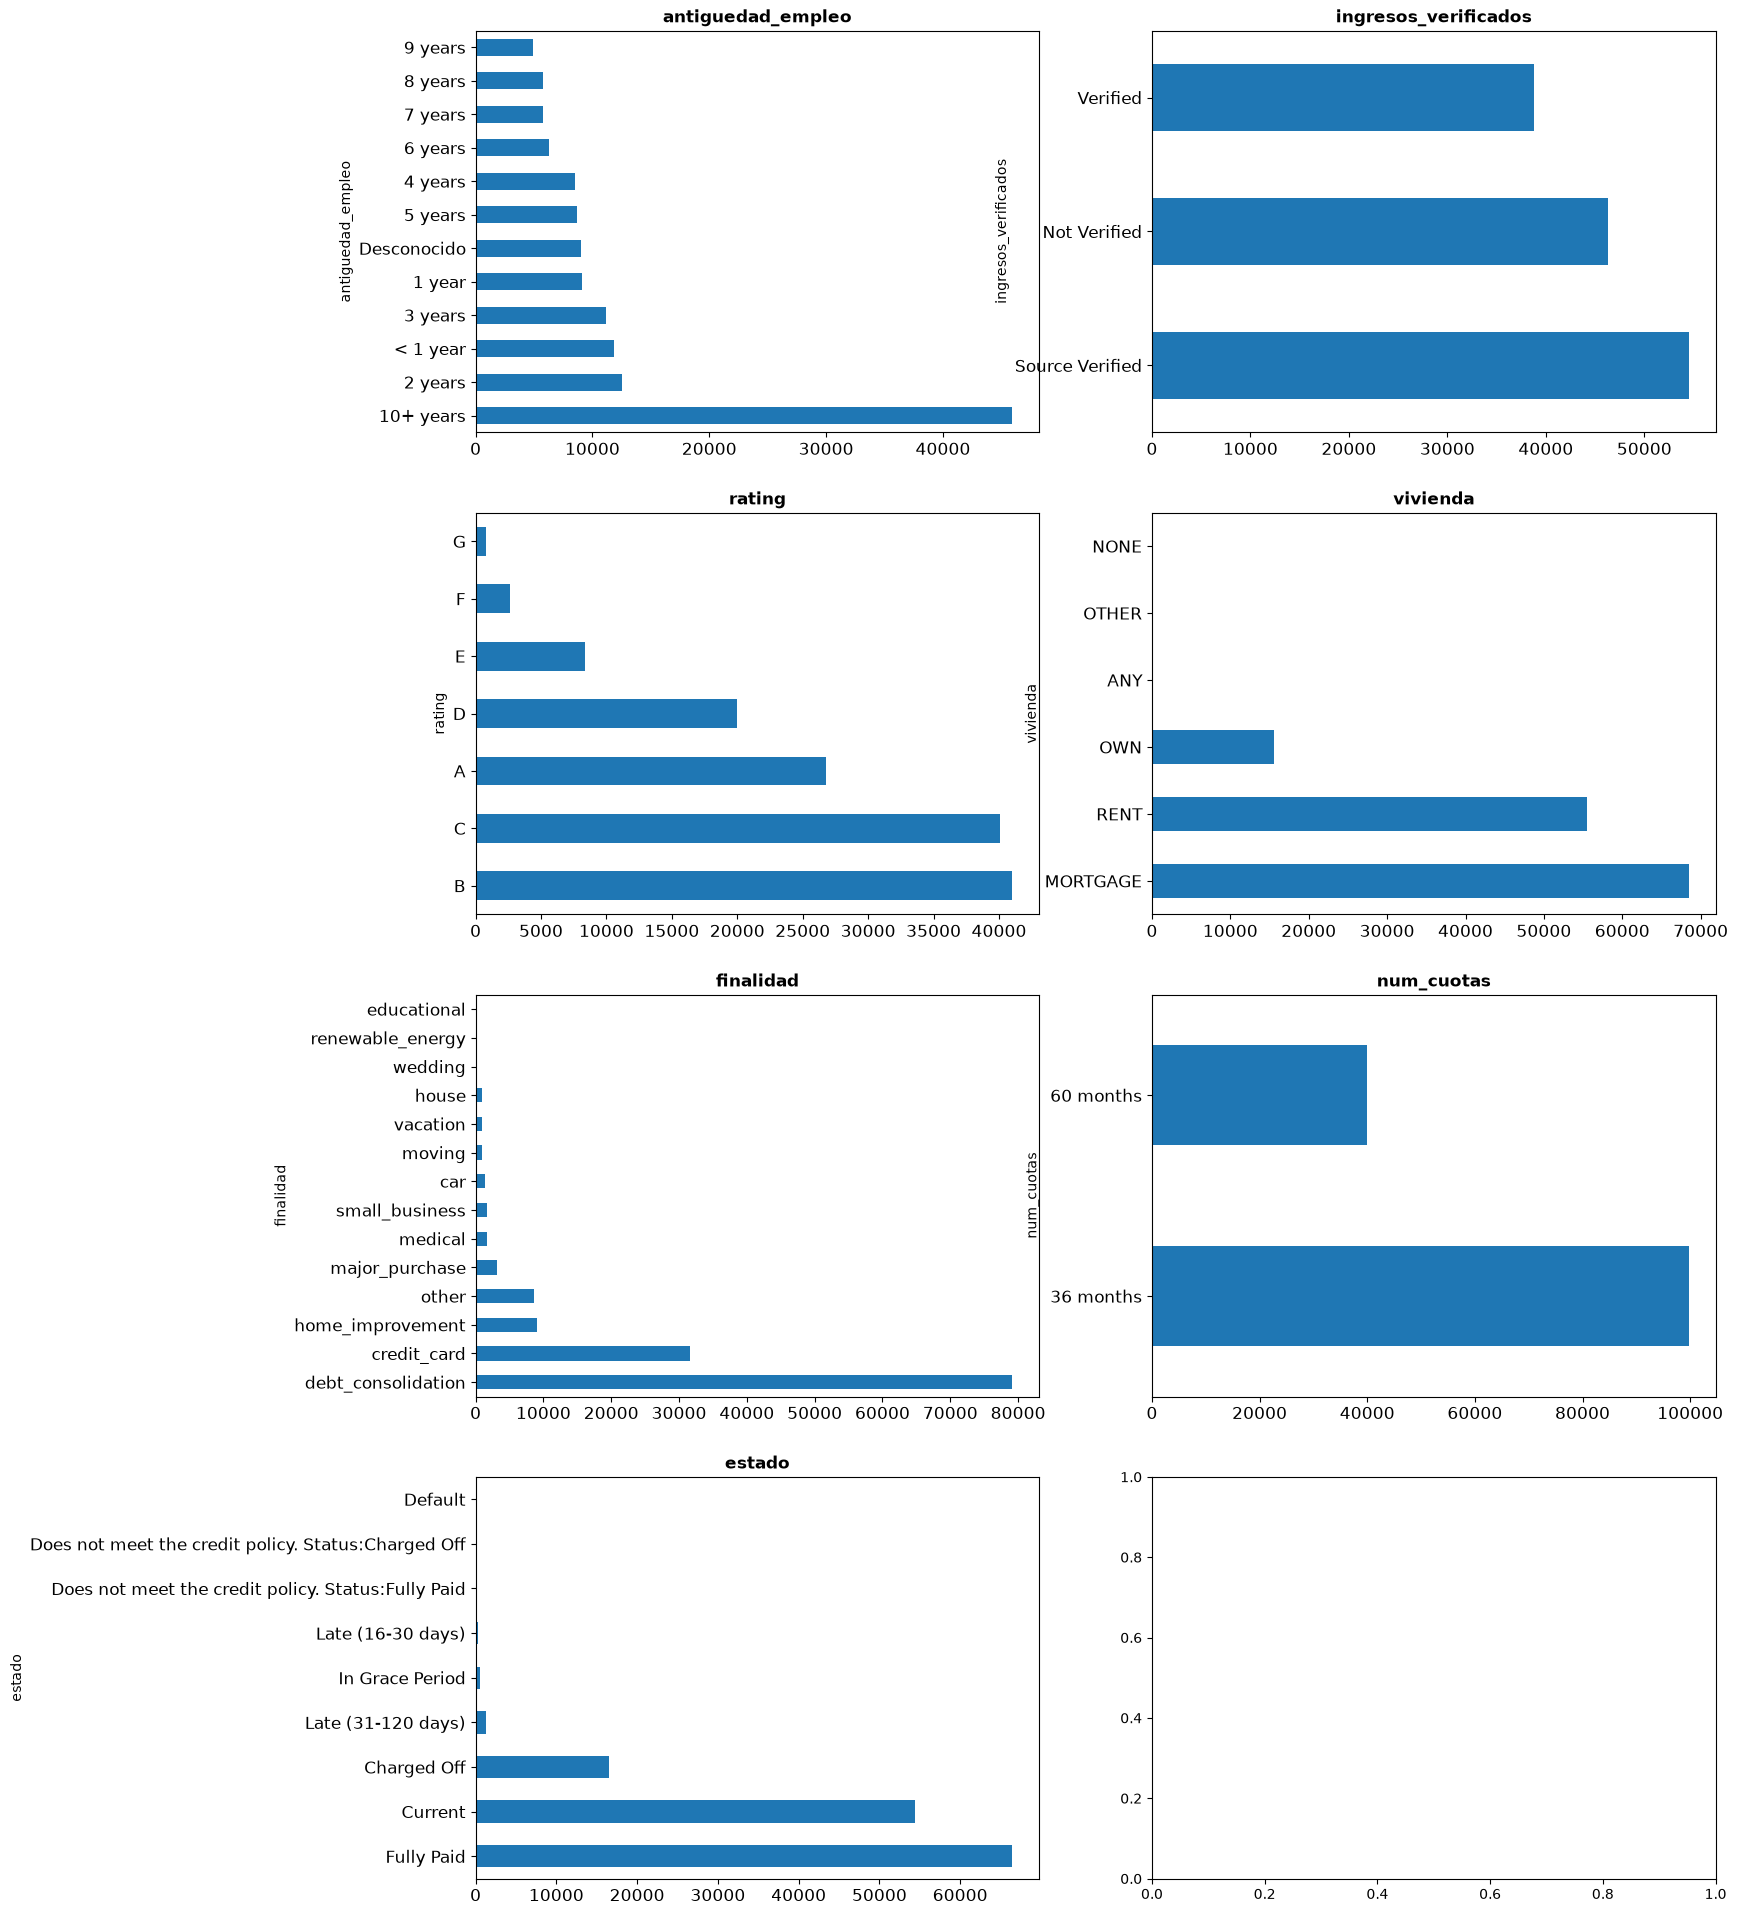

In [49]:
graficos_eda_categoricos(cat[variables])

##### Conclusiones :
En transformacion :
- En Vivienda juntar ANY, NONE, OTHER a la categoria mayoritaria
- En finalidad juntar renowable_energy, educational y wedding en otros
- Crear la tarjeta a partir de estado

## EDA NUMERICAS

### Analisis Estadistico

In [50]:
def estadisticos_cont(df_cont):
    # describe() traspuesto: una fila por variable
    estadisticos = df_cont.describe().T

    # Añadir la mediana
    estadisticos['median'] = df_cont.median()

    # Reordenar para que la mediana quede pegada a la media
    estadisticos = estadisticos.iloc[:, [0, 1, 8, 2, 3, 4, 5, 6, 7]]

    return estadisticos

In [51]:
estadisticos_cont(num)

,count,mean,median,std,min,25%,50%,75%,max
id_cliente,139602.000,80323605.352,84507208.500,44908823.918,65640.000,45184803.250,84507208.500,122300455.500,145637006.000
ingresos,139602.000,76164.630,65000.000,45612.082,0.000,46000.000,65000.000,92973.500,400000.000
dti,139602.000,18.814,17.810,14.418,-1.000,11.940,17.810,24.440,999.000
num_hipotecas,139602.000,1.509,1.000,1.876,0.000,0.000,1.000,2.000,32.000
num_lineas_credito,139602.000,11.608,11.000,5.646,0.000,8.000,11.000,14.000,91.000
porc_tarjetas_75p,139602.000,41.069,33.300,36.421,0.000,0.000,33.300,66.700,100.000
porc_uso_revolving,139602.000,50.319,50.300,24.695,0.000,31.700,50.300,69.200,366.600
num_cancelaciones_12meses,139602.000,0.009,0.000,0.108,0.000,0.000,0.000,0.000,7.000
num_derogatorios,139602.000,0.198,0.000,0.575,0.000,0.000,0.000,0.000,46.000
num_meses_desde_ult_retraso,139602.000,16.833,0.000,23.060,0.000,0.000,0.000,31.000,195.000


### Analisis Grafico

In [52]:
def graficos_eda_continuas(df_cont):
    from math import ceil

    # Filas necesarias para repartir las variables en 2 columnas
    filas = ceil(df_cont.shape[1] / 2)

    # Rejilla de subgráficos
    f, ax = plt.subplots(nrows=filas, ncols=2, figsize=(16, filas * 6))

    # Aplanar para recorrer la rejilla como si fuera de 1 dimensión
    ax = ax.flat

    # Un gráfico de densidad por variable
    for cada, variable in enumerate(df_cont):
        df_cont[variable].plot.density(ax=ax[cada])
        ax[cada].set_title(variable, fontsize=12, fontweight='bold')
        ax[cada].tick_params(labelsize=12)


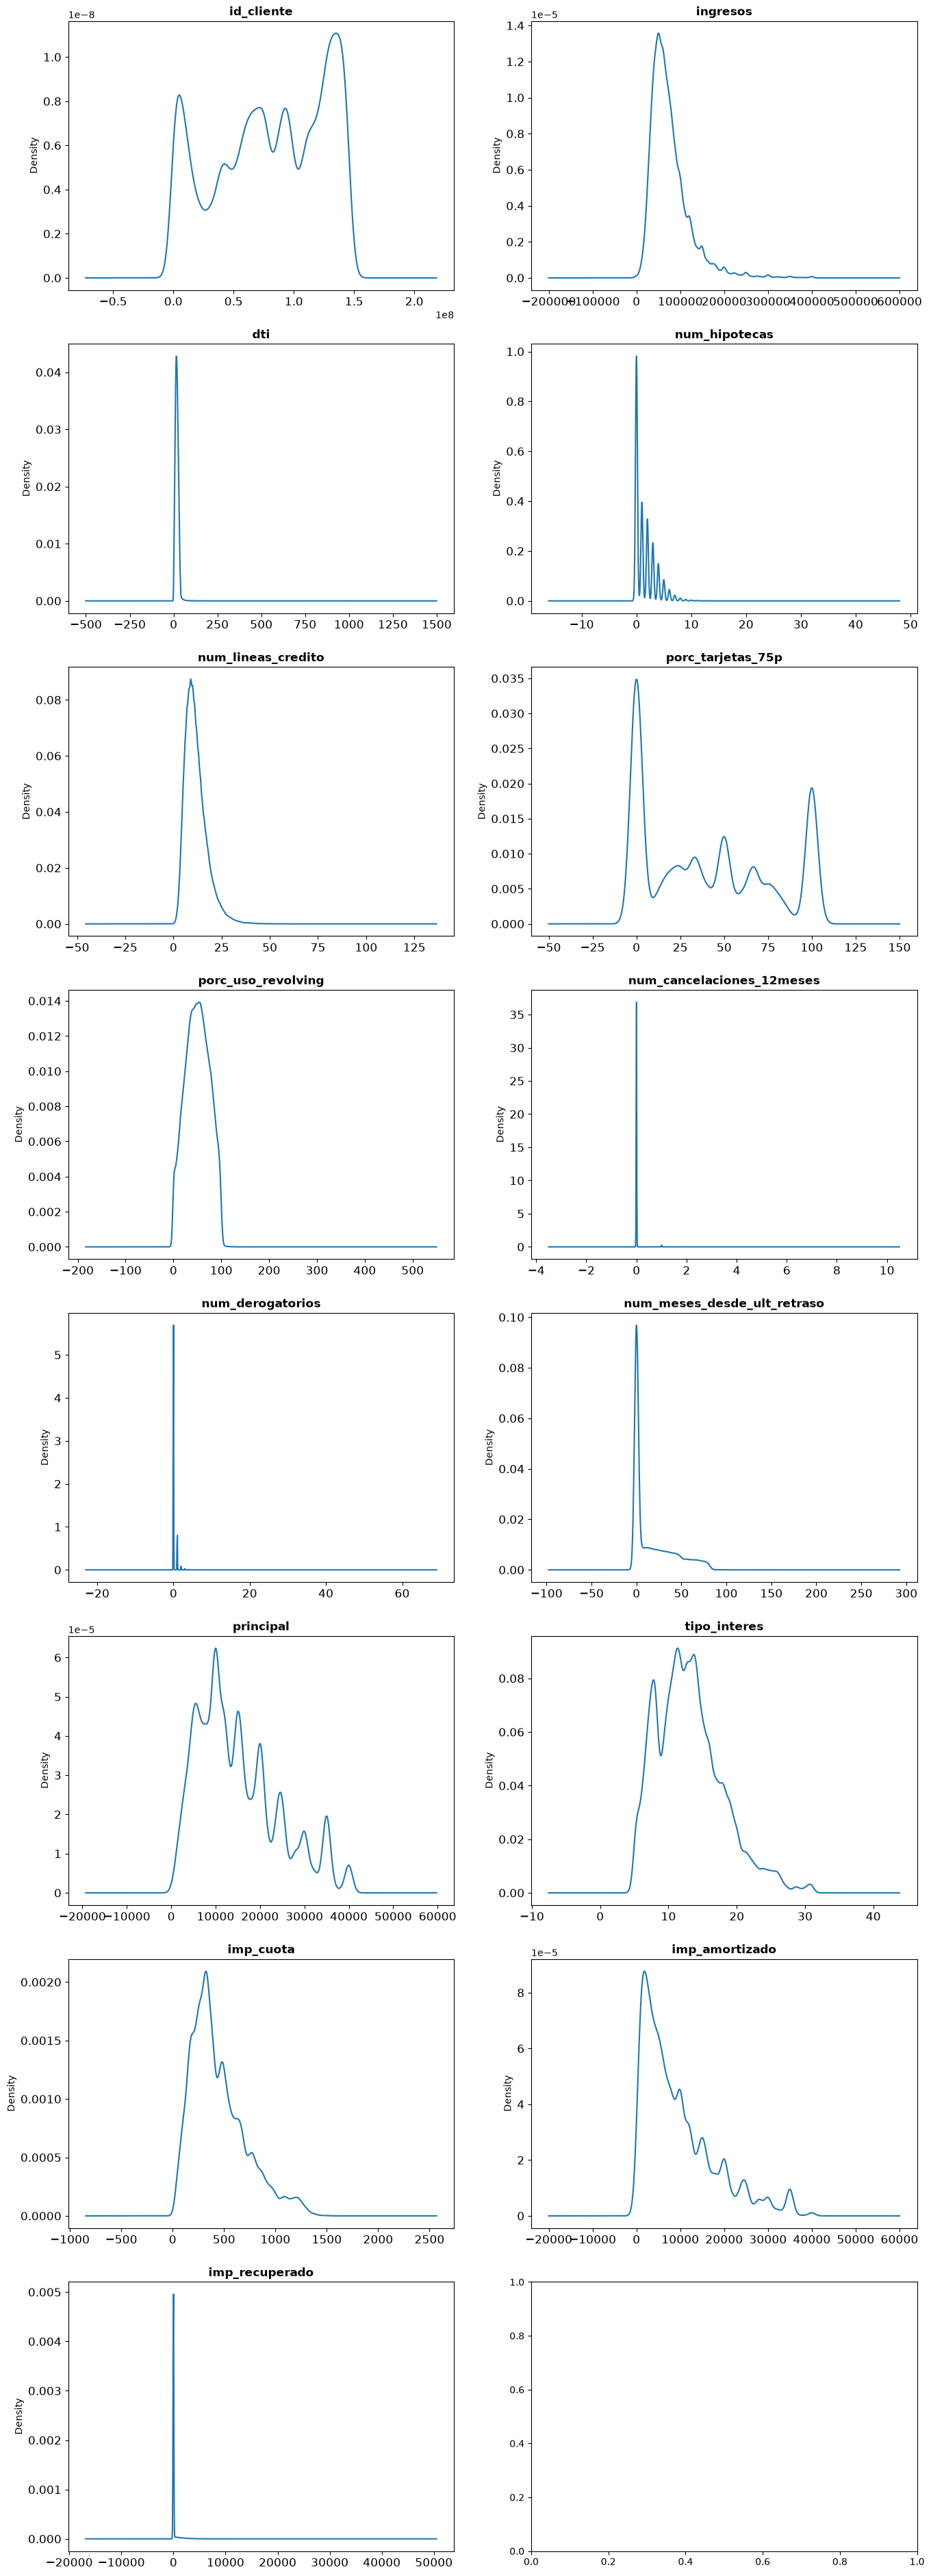

In [53]:
graficos_eda_continuas(num)

A Analizar el detalle de imp_amortizado e imp_recaudado ya que son relevantes para el modelo LGD

In [54]:
ratios = num[['principal','imp_amortizado','imp_recuperado']]

In [55]:
ratios['r_amortizado_principal'] = ratios['imp_amortizado'] / ratios['principal']
ratios['r_recuperado_principal'] = ratios['imp_recuperado'] / ratios['principal']
ratios.describe().T

,count,mean,std,min,25%,50%,75%,max
principal,139602.000,15032.704,9192.178,500.000,8000.000,12800.000,20000.000,40000.000
imp_amortizado,139602.000,9490.758,8283.876,0.000,3012.783,7000.000,13775.000,40000.000
imp_recuperado,139602.000,146.360,773.982,0.000,0.000,0.000,0.000,33666.340
r_amortizado_principal,139602.000,0.663,0.369,0.000,0.275,0.871,1.000,1.000
r_recuperado_principal,139602.000,0.009,0.041,0.000,0.000,0.000,0.000,1.221


#### Conclusiones

- dti : valores negativos superiores a 100 no tienen sentido de negocio y deben ser tratados como atipicos
- num_hipotecas : valores superiores a 6 son extremadamente raros y probablemente errores.
- porc_uso_revolving : valores superiores a 100% no son posibles y deben considerarse errores (no hay casuistica)
- Para estas variables , se recomienda winsorizar los limites indicados 
- En transformacion, convertir num_derogatorios a binaria
- imp_recuperado hasta despues del percentil 75 es que existe cierta recuperacion, esto aporta un punto notable a el modelo LGD. Pero tambien en el conteo del describe son las mismas personas del dataframe, asi que con total seguridad una muy gran parte no cayo en default, asi que hay revisar en profundidad la relacion entre **estado** e **imp_recuperado**


In [56]:
# Winsorizar las variables numericas con valores atipicos en el DataFrame num
import numpy as np
num['dti'] = np.clip(num['dti'],0,100)
num['num_hipotecas'] =np.clip(num['num_hipotecas'],0,7)
num['porc_uso_revolving'] = np.clip(num['porc_uso_revolving'],0,100)

##### Analisis del cruce entre estado e importe recuperado (Bivariado)

In [57]:
temp = cat.merge(
    num,
    left_index=True,
    right_index=True,
    how='left'
)
temp.groupby('estado')['imp_recuperado'].mean()

estado
Charged Off                                           1237.570
Current                                                  0.000
Default                                                  0.000
Does not meet the credit policy. Status:Charged Off    440.341
Does not meet the credit policy. Status:Fully Paid       0.000
Fully Paid                                               0.000
In Grace Period                                          0.000
Late (16-30 days)                                        0.000
Late (31-120 days)                                       0.000
Name: imp_recuperado, dtype: float64

Efectivamente, solo hay un importe recuperado en el estado charged-off. (De los Malos)

## GUARDAR DATASETS TRAS EDA

In [58]:
cat.to_pickle(ENTRENAMIENTO/"cat_eda.pkl")
num.to_pickle(ENTRENAMIENTO/"num_eda.pkl")

In [59]:
cat.info()
num.info()

<class 'pandas.DataFrame'>
Index: 139602 entries, 0 to 139999
Data columns (total 7 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   antiguedad_empleo     139602 non-null  str  
 1   ingresos_verificados  139602 non-null  str  
 2   rating                139602 non-null  str  
 3   vivienda              139602 non-null  str  
 4   finalidad             139602 non-null  str  
 5   num_cuotas            139602 non-null  str  
 6   estado                139602 non-null  str  
dtypes: str(7)
memory usage: 16.6 MB
<class 'pandas.DataFrame'>
Index: 139602 entries, 0 to 139999
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id_cliente                   139602 non-null  int64  
 1   ingresos                     139602 non-null  float64
 2   dti                          139602 non-null  float64
 3   num_hipotecas           